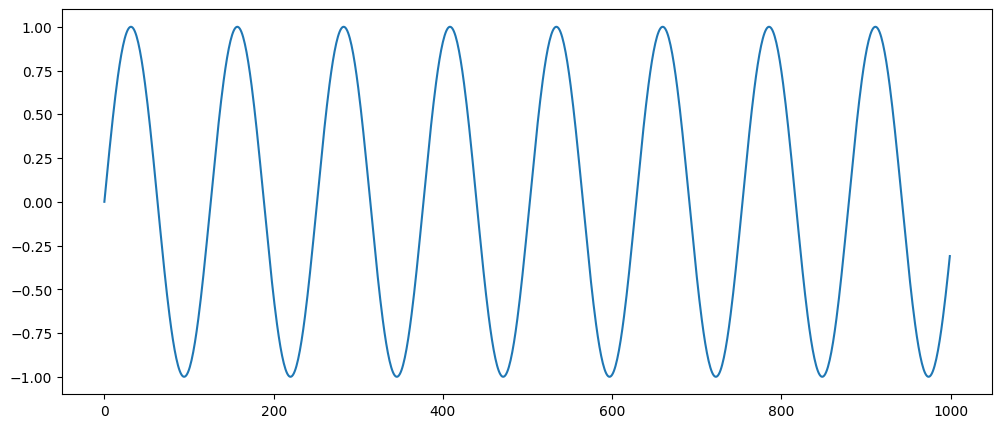

In [2]:
import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt

data = np.sin(np.arange(1000) * 0.05)

plt.figure(figsize=(12,5))
plt.plot(data)
plt.show()



In [8]:
seq_length = 10

X = []
y = []

for i in range(len(data) -seq_length):
  X.append(data[i : i + seq_length])
  y.append(data[i + seq_length])


X = np.array(X)
y = np.array(y)

print(X.shape)
print(y.shape)

(990, 10)
(990,)


In [22]:
from re import split
X = torch.tensor(X, dtype=torch.float32)
y = torch.tensor(y, dtype=torch.float32)

print(X.shape)
print(y.shape)





torch.Size([990, 10, 1])
torch.Size([990])


/tmp/ipykernel_4130/2622255126.py:2: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  X = torch.tensor(X, dtype=torch.float32)
/tmp/ipykernel_4130/2622255126.py:3: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  y = torch.tensor(y, dtype=torch.float32)


In [23]:
split_indx = int(len(X) * 0.8) # 80 % Data ko split kiya for training

X_train = X[:split_indx] # MEANS 0 INDEX TO 80% INDEX IN TRAIING
y_train = y[:split_indx] # Y IS TARGET IN Y ALSO SAME THING LIKE X || MEANS FROM INDEX 0 TO INDEX 80% FOR TRAINING

X_test = X[split_indx:] # MEANS FROM 80% TO END FOR TESTING
y_test = y[split_indx:]

print(X_train.shape)
print(y_train.shape)
print(X_test.shape)
print(y_test.shape)

torch.Size([792, 10, 1])
torch.Size([792])
torch.Size([198, 10, 1])
torch.Size([198])


In [25]:
class MyRNN(nn.Module):

  def __init__(self):
    super().__init__()

    self.rnn = nn.RNN(
        input_size =  1,
        hidden_size = 16,
        batch_first = True
    )
    self.fc = nn.Linear(16, 1)

  def forward(self,x):

    output, hidden = self.rnn(x)

    final_hidden = hidden.squeeze(0)

    prediction = self.fc(final_hidden)

    return prediction.squeeze(1)


model = MyRNN()

loss_fuctn = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr = 0.001)

print(model)


MyRNN(
  (rnn): RNN(1, 16, batch_first=True)
  (fc): Linear(in_features=16, out_features=1, bias=True)
)


In [27]:
epochs = 100

for epoch in range(epochs):

  prediction = model(X_train)

  loss = loss_fuctn(prediction, y_train)

  optimizer.zero_grad()

  loss.backward()

  optimizer.step()

  if(epoch + 1 )% 10 == 0:
    print(f"EPOCH: {epoch + 1}, LOSS {loss.item():.6f} ")



EPOCH: 10, LOSS 0.353962 
EPOCH: 20, LOSS 0.286581 
EPOCH: 30, LOSS 0.212280 
EPOCH: 40, LOSS 0.126748 
EPOCH: 50, LOSS 0.043454 
EPOCH: 60, LOSS 0.010268 
EPOCH: 70, LOSS 0.014263 
EPOCH: 80, LOSS 0.008600 
EPOCH: 90, LOSS 0.008787 
EPOCH: 100, LOSS 0.007787 


In [28]:
model.eval()

with torch.no_grad():

  prediction = model(X_test)

  print("Actual:", y_test[:10])
  print("Predicted:", prediction[:10])


Actual: tensor([0.6748, 0.6371, 0.5978, 0.5569, 0.5147, 0.4712, 0.4266, 0.3808, 0.3342,
        0.2866])
Predicted: tensor([0.7402, 0.7147, 0.6872, 0.6579, 0.6265, 0.5931, 0.5577, 0.5202, 0.4808,
        0.4393])


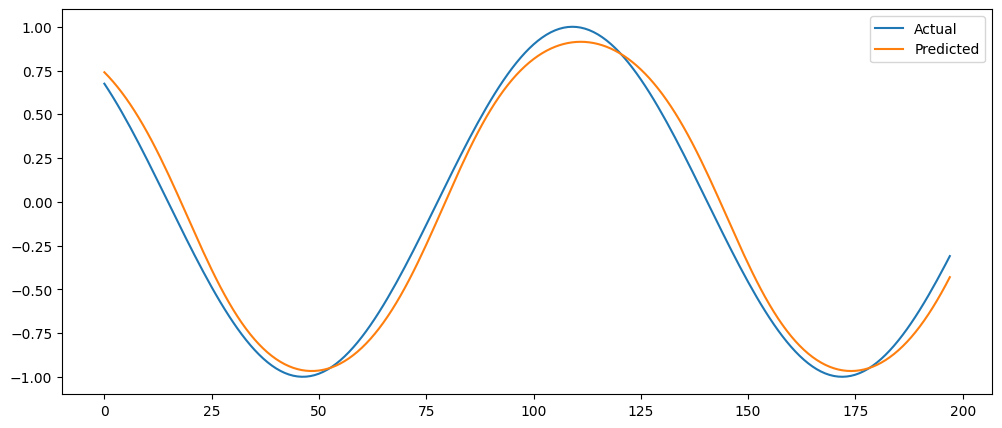

In [32]:
plt.figure(figsize=(12, 5))

plt.plot(y_test.numpy(), label="Actual")

plt.plot(prediction.numpy(), label="Predicted")

plt.legend()

plt.show()

In [33]:
from sklearn.metrics import mean_absolute_error

mae = mean_absolute_error(
    y_test.numpy(),
    prediction.numpy()
)

print(mae)


0.08195307105779648


In [34]:
torch.save(model.state_dict(), "rnn_model.pth")

In [ ]:
loaded_model = MyRNN()

loaded_model.load_state_dict(
    torch.load("rnn_model.pth", weights_only=True)
)

loaded_model.eval()